In [9]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

# Q1.
**Method1: use pandas.DataFrame.corr**

In [10]:
data = {
    'Feature1': [0.3510, 2.1812, 0.2415, -0.1096, 0.1544],
    'Feature2': [1.1796, 2.1068, 1.7753, 1.2747, 2.0851],
    'Feature3': [-0.9852, 1.3766, -1.3244, -0.6316, -0.8320],
    'Target y': [0.2758, 1.4392, -0.4611, 0.6154, 1.0006]
}
df_data = pd.DataFrame(data)
print(df_data)

   Feature1  Feature2  Feature3  Target y
0    0.3510    1.1796   -0.9852    0.2758
1    2.1812    2.1068    1.3766    1.4392
2    0.2415    1.7753   -1.3244   -0.4611
3   -0.1096    1.2747   -0.6316    0.6154
4    0.1544    2.0851   -0.8320    1.0006


In [11]:
print(df_data.corr('pearson'))

          Feature1  Feature2  Feature3  Target y
Feature1  1.000000  0.540770  0.923239  0.598772
Feature2  0.540770  1.000000  0.471446  0.453692
Feature3  0.923239  0.471446  1.000000  0.800892
Target y  0.598772  0.453692  0.800892  1.000000


**Method2: use numpy.corrcoef**

In [12]:
np_data = np.array([
    [0.3510, 2.1812, 0.2415, -0.1096, 0.1544],
    [1.1796, 2.1068, 1.7753, 1.2747, 2.0851],
    [-0.9852, 1.3766, -1.3244, -0.6316, -0.8320],
    [0.2758, 1.4392, -0.4611, 0.6154, 1.0006]
])
print(np_data)

[[ 0.351   2.1812  0.2415 -0.1096  0.1544]
 [ 1.1796  2.1068  1.7753  1.2747  2.0851]
 [-0.9852  1.3766 -1.3244 -0.6316 -0.832 ]
 [ 0.2758  1.4392 -0.4611  0.6154  1.0006]]


In [13]:
# rowvar is set to be True (default) since each row is a feature(variable), while each column is a datapoint
np_corr = np.corrcoef(np_data)
print(np_corr)

[[1.         0.54077001 0.92323852 0.59877228]
 [0.54077001 1.         0.47144555 0.45369219]
 [0.92323852 0.47144555 1.         0.80089165]
 [0.59877228 0.45369219 0.80089165 1.        ]]


**Method3: use scipy.stats.pearsonr**

In [14]:
feature1 = np_data[0]
feature2 = np_data[1]
feature3 = np_data[2]
target = np_data[3]
print(f'sample feature1: {feature1}')

R1t = scipy.stats.pearsonr(feature1,target)
R2t = scipy.stats.pearsonr(feature2,target)
R3t = scipy.stats.pearsonr(feature3,target)
print(R1t)
print(R2t)
print(R3t)

sample feature1: [ 0.351   2.1812  0.2415 -0.1096  0.1544]
PearsonRResult(statistic=np.float64(0.5987722845227617), pvalue=np.float64(0.2860082394909362))
PearsonRResult(statistic=np.float64(0.45369218508997844), pvalue=np.float64(0.4428203489100863))
PearsonRResult(statistic=np.float64(0.8008916458435773), pvalue=np.float64(0.10340754695492256))


**visualize the distribution**

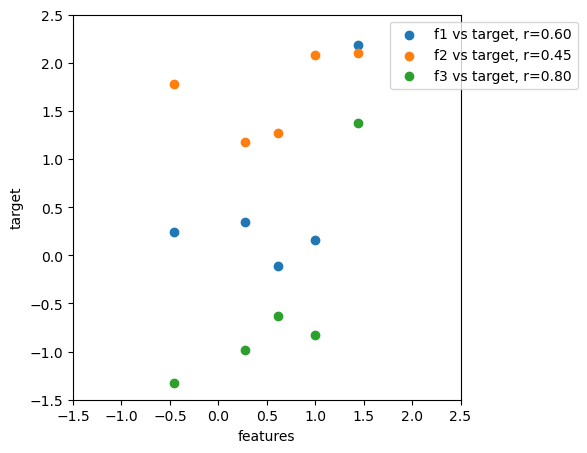

In [7]:
plt.figure(figsize=[5,5])

plt.scatter(target, feature1, label=f'f1 vs target, r={R1t[0]:.2f}')
plt.scatter(target, feature2, label=f'f2 vs target, r={R2t[0]:.2f}')
plt.scatter(target, feature3, label=f'f3 vs target, r={R3t[0]:.2f}')

plt.xlim([-1.5, 2.5])
plt.ylim([-1.5, 2.5])
plt.xlabel('features')
plt.ylabel('target')

plt.legend(bbox_to_anchor=(0.8, 1))
plt.show()

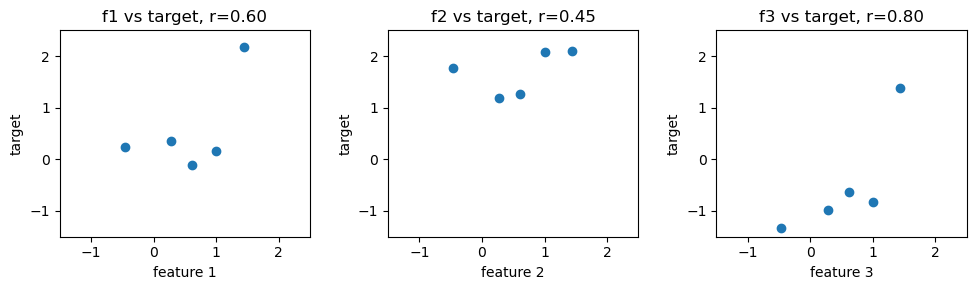

In [17]:
figure, axs = plt.subplots(1,3, figsize=(10,3))
axs[0].scatter(target, feature1)
axs[0].set_title(f'f1 vs target, r={R1t[0]:.2f}')
axs[0].set_xlabel('feature 1')
axs[0].set_ylabel('target')

axs[1].scatter(target, feature2)
axs[1].set_title(f'f2 vs target, r={R2t[0]:.2f}')
axs[1].set_xlabel('feature 2')
axs[1].set_ylabel('target')

axs[2].scatter(target, feature3)
axs[2].set_title(f'f3 vs target, r={R3t[0]:.2f}')
axs[2].set_xlabel('feature 3')
axs[2].set_ylabel('target')

plt.setp(axs, xlim=[-1.5, 2.5], ylim=[-1.5,2.5])
plt.tight_layout()
plt.show()

# Q2.

In [1]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
import numpy as np

**key in the training dataset and testing dataset**

In [3]:
X_train = np.array([[-10],
                    [-8],
                    [-3],
                    [-1],
                    [2],
                    [7]])
y_train = np.array([[4.18],[2.42],[0.22],[0.12],[0.25],[3.09]])

X_test = np.array([[-9],[-7],[-5],[-4],[-2],[1],[4],[5],[6],[9]])
y_test = np.array([[3],[1.81],[0.80],[0.25],[-0.19],[0.4],[1.24],[1.68],[2.32],[5.05]])

*Note that order of 1 polynomial regression will be linear regression*

In [4]:
poly = PolynomialFeatures(1)
P1 = poly.fit_transform(X_train)
print(P1)

[[  1. -10.]
 [  1.  -8.]
 [  1.  -3.]
 [  1.  -1.]
 [  1.   2.]
 [  1.   7.]]


**Use the `PolyReg` function defined in Tut5 to train and test the model**

In [5]:
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures

def PolyReg(X_train: np.ndarray, 
            y_train: np.ndarray, 
            X_test: np.ndarray = None, 
            y_test: np.ndarray = None, 
            n: int = 1, 
            lmd: float = 0.0):
    '''
    Perform linear regression or polynomial regression, with or without L2 regularization (ridge regression)

    Parameter
    ---
    n : int
        order of regression (default n=1: linear regression)
    X_train : np.ndarray
        raw training features (m*d), one row is one sample
    y_train : np.ndarray
        raw training labels (m*n), one row is one sample
    X_test : np.ndarray
        raw test features
    y_test : np.ndarray
        raw test labels
    lmd : float
        L2 regularization (ridge)
    '''
    poly = PolynomialFeatures(n)
    Ptr = poly.fit_transform(X_train)

    if n == 1:
        print('Performing linear regression...')
    else:
        print(f'Performing polynomial regression with order {n}...')
    
    if lmd == 0.0:
        print('No regularization')
    else:
        print(f'Performing ridge regression with lambda = {lmd}...')

    if Ptr.shape[0] > Ptr.shape[1]:
        # if tall, use primal
        w = np.linalg.inv(Ptr.T @ Ptr + lmd*np.identity(Ptr.shape[1])) @ Ptr.T @ y_train
    else:
        # if wide, use dual
        w = Ptr.T @ np.linalg.inv(Ptr @ Ptr.T + lmd*np.identity(Ptr.shape[0])) @ y_train
        
    # use trained w to see the MSE of training data
    y_train_hat = Ptr@w
    MSE_train = mean_squared_error(y_train, y_train_hat)

    MSE_test = None
    if X_test is not None and y_test is not None:
        Pts = poly.transform(X_test)
        # use trained w to make predictions based on X_test, calculate the MSE of prediction
        y_test_pred = Pts@w
        MSE_test = mean_squared_error(y_test, y_test_pred)
    
    return w, MSE_train, MSE_test

In [6]:
w = [0]*6
MSE_train = [0]*6
MSE_test = [0]*6

w_lmd = [0]*6
MSE_train_lmd = [0]*6
MSE_test_lmd = [0]*6

for n in range(1,7):
    w[n-1], MSE_train[n-1], MSE_test[n-1] = PolyReg(X_train, y_train, X_test, y_test, n, lmd=0)
    w_lmd[n-1], MSE_train_lmd[n-1], MSE_test_lmd[n-1] = PolyReg(X_train, y_train, X_test, y_test, n, lmd=1)

Performing linear regression...
No regularization
Performing linear regression...
Performing ridge regression with lambda = 1...
Performing polynomial regression with order 2...
No regularization
Performing polynomial regression with order 2...
Performing ridge regression with lambda = 1...
Performing polynomial regression with order 3...
No regularization
Performing polynomial regression with order 3...
Performing ridge regression with lambda = 1...
Performing polynomial regression with order 4...
No regularization
Performing polynomial regression with order 4...
Performing ridge regression with lambda = 1...
Performing polynomial regression with order 5...
No regularization
Performing polynomial regression with order 5...
Performing ridge regression with lambda = 1...
Performing polynomial regression with order 6...
No regularization
Performing polynomial regression with order 6...
Performing ridge regression with lambda = 1...


**Visualize the result separatly**

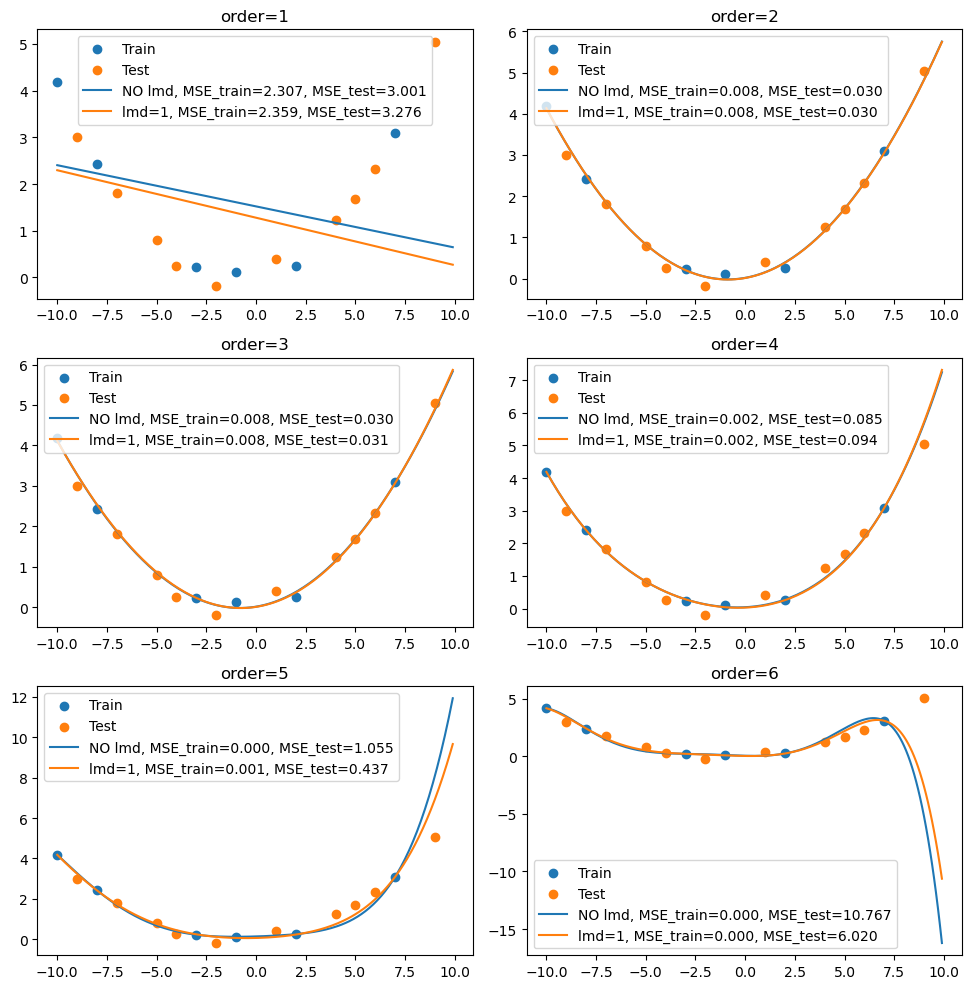

In [7]:
import matplotlib.pyplot as plt
xx = np.arange(-10,10,0.1).reshape(-1,1)
fig = plt.figure(figsize = (10,10))

for i in range(len(w)):
    poly = PolynomialFeatures(i+1)
    pp = poly.fit_transform(xx)
    yy = pp @ w[i]
    yy_lmd = pp @ w_lmd[i]
    
    ax = fig.add_subplot(3,2,i+1)
    ax.scatter(X_train, y_train, label='Train')
    ax.scatter(X_test, y_test, label='Test')
    ax.plot(xx, yy, label=f'NO lmd, MSE_train={MSE_train[i]:.3f}, MSE_test={MSE_test[i]:.3f}')
    ax.plot(xx, yy_lmd, label=f'lmd=1, MSE_train={MSE_train_lmd[i]:.3f}, MSE_test={MSE_test_lmd[i]:.3f}')
    ax.set_title(f'order={i+1}')
    ax.legend()
plt.tight_layout()
plt.show()

**Or you can try the other visualization**

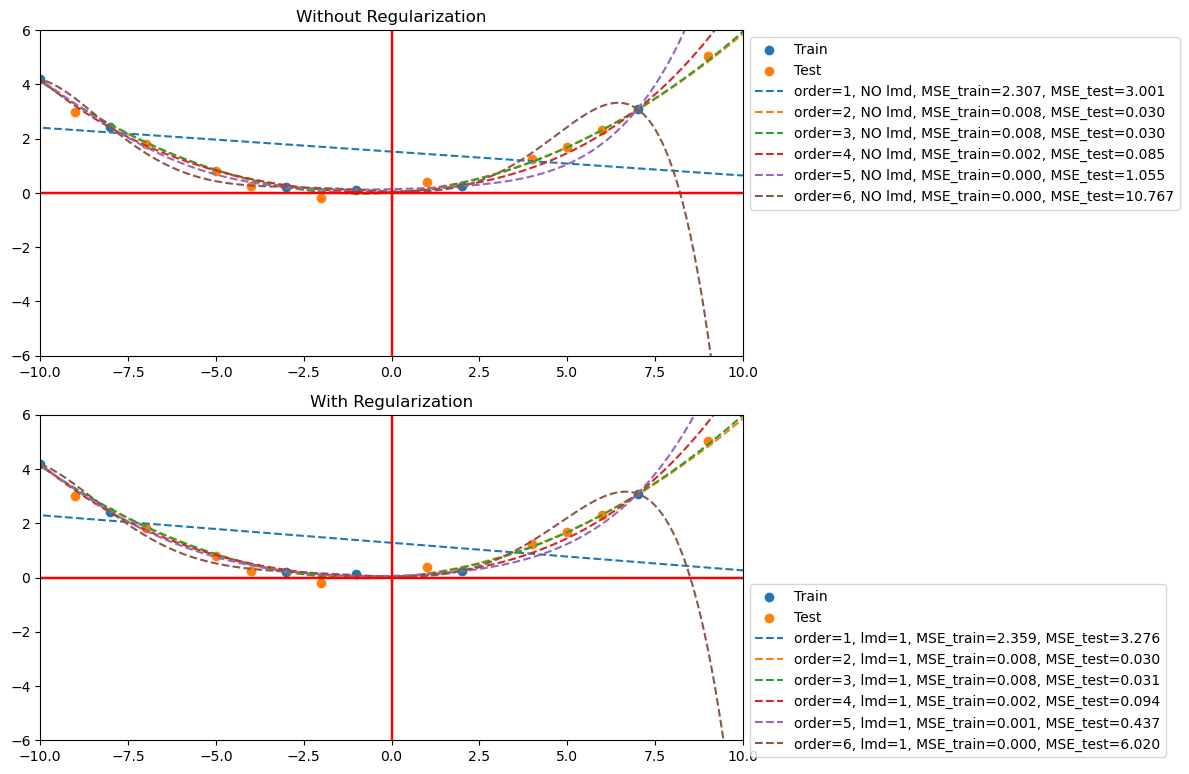

In [7]:
xx = np.arange(-12,12,0.1).reshape(-1,1)

fig, axs = plt.subplots(2,1,figsize = (12,8))
axs[0].scatter(X_train, y_train, label='Train')
axs[0].scatter(X_test, y_test, label='Test')
axs[1].scatter(X_train, y_train, label='Train')
axs[1].scatter(X_test, y_test, label='Test')

for i in range(len(w)):
    poly = PolynomialFeatures(i+1)
    pp = poly.fit_transform(xx)
    yy = pp @ w[i]
    yy_lmd = pp @ w_lmd[i]
    
    axs[0].plot(xx, yy, '--', label=f'order={i+1}, NO lmd, MSE_train={MSE_train[i]:.3f}, MSE_test={MSE_test[i]:.3f}')
    axs[0].set_ylim([-6,6])
    axs[0].set_xlim([-10,10])
    axs[0].axhline(0, color='red', linestyle = '-')
    axs[0].axvline(0, color='red', linestyle = '-')
    axs[0].set_title('Without Regularization')
    axs[0].legend(bbox_to_anchor=(1, 1))
    
    axs[1].plot(xx, yy_lmd, '--', label=f'order={i+1}, lmd=1, MSE_train={MSE_train_lmd[i]:.3f}, MSE_test={MSE_test_lmd[i]:.3f}')
    axs[1].set_ylim([-6,6])
    axs[1].set_xlim([-10,10])
    axs[1].axhline(0, color='red', linestyle = '-')
    axs[1].axvline(0, color='red', linestyle = '-')
    axs[1].set_title('With Regularization')
    axs[1].legend(bbox_to_anchor=(1, 0.5))
    
plt.tight_layout()
plt.show()

**Visualize MSE**

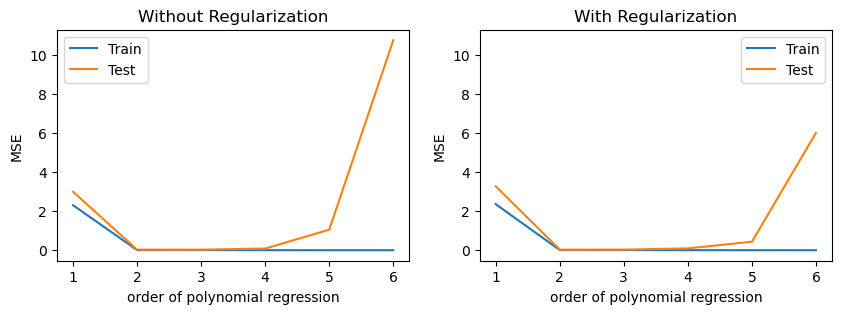

In [8]:
n = range(1,7)
fig, axs = plt.subplots(1,2, figsize=(10,3))
axs[0].plot(n, MSE_train, label='Train')
axs[0].plot(n, MSE_test, label='Test')
axs[0].set_title('Without Regularization')
axs[0].set_xlabel('order of polynomial regression')
axs[0].set_ylabel('MSE')
axs[0].legend()

axs[1].plot(n, MSE_train_lmd, label='Train')
axs[1].plot(n, MSE_test_lmd, label='Test')
axs[1].set_title('With Regularization')
axs[1].set_xlabel('order of polynomial regression')
axs[1].set_ylabel('MSE')
axs[1].sharey(axs[0])
axs[1].legend()

plt.show()